## objective : To build and evaluate a simple model that forecasts Walmart’s total daily sales using historical sales data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
sales_df = pd.read_csv("../data/raw/sales_train_evaluation.csv")
calendar_df = pd.read_csv("../data/raw/calendar.csv")

In [3]:
daily_cons = [col for col in sales_df.columns if col.startswith('d_')]

In [4]:
daily_sales = sales_df[daily_cons].sum()
daily_sales.index = pd.to_datetime(calendar_df.set_index('d').loc[daily_sales.index, 'date'])

In [5]:
daily_sales.head()

date
2011-01-29    32631
2011-01-30    31749
2011-01-31    23783
2011-02-01    25412
2011-02-02    19146
dtype: int64

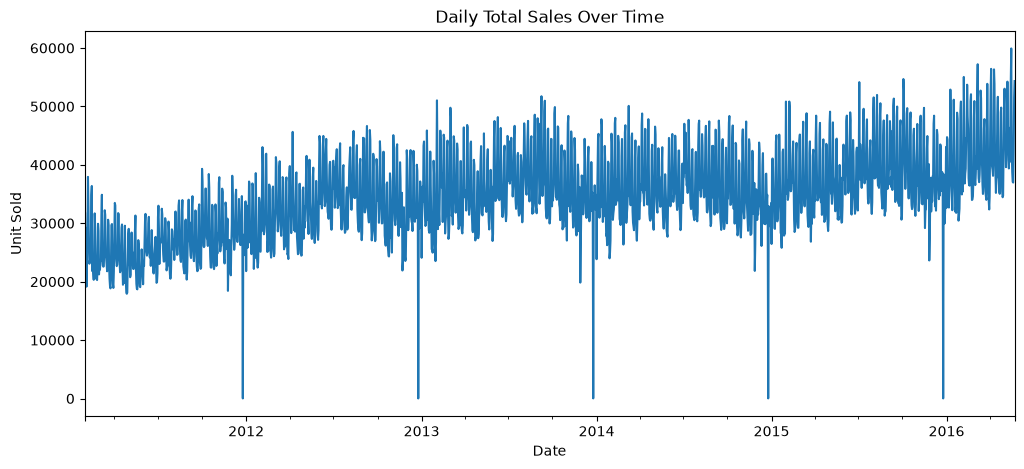

In [6]:
daily_sales.plot(figsize=(12,5))
plt.title('Daily Total Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Unit Sold')
plt.show()

In [7]:
train = daily_sales.iloc[:-28]
test = daily_sales.iloc[-28:]

print("Training days:", len(train))
print("Test days:", len(test))
print('Test period:', test.index.min().date(), 'to', test.index.max().date())

Training days: 1913
Test days: 28
Test period: 2016-04-25 to 2016-05-22


In [8]:
forecast = pd.Series(train.mean(), index=test.index)

forecast.head()

date
2016-04-25    34341.562467
2016-04-26    34341.562467
2016-04-27    34341.562467
2016-04-28    34341.562467
2016-04-29    34341.562467
dtype: float64

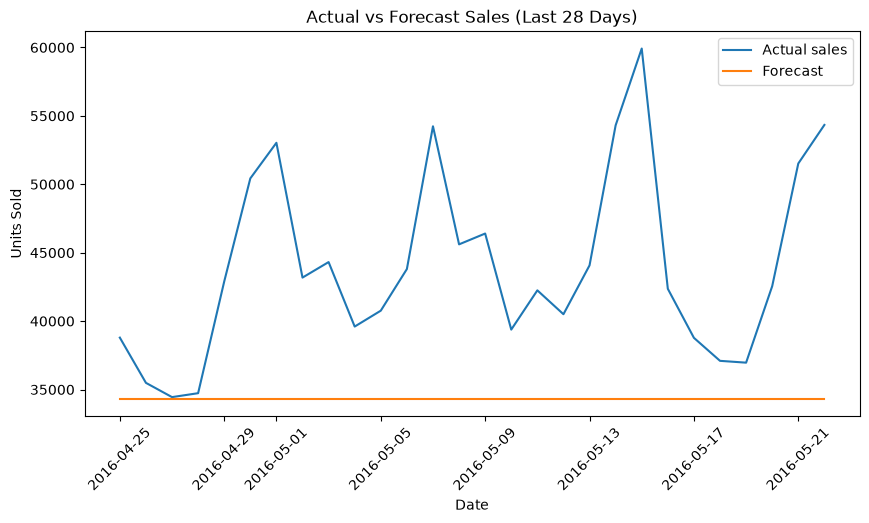

In [9]:
plt.figure(figsize=(10,5))
plt.plot(test.index, test.values, label="Actual sales")
plt.plot(forecast.index, forecast.values, label="Forecast")

plt.title("Actual vs Forecast Sales (Last 28 Days)")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.legend()



In [10]:

mae = (test - forecast).abs().mean()
print("Mean Absolute Error:", round(mae, 2))

Mean Absolute Error: 9650.01


Conclusion: The baseline forecast predicted about 34,342 units per day.
            Its average error over the 28 test days was about 9,650 units per day.
